
# Project: Loan Default Prediction

**Explainable AI:** SHAP (global + local), LIME, permutation importance, partial dependence, reason codes  
**MLOps:** MLflow experiment tracking, dataset versioning, quality gate, model registry with champion/challenger promotion, prediction logging, drift + *explanation-drift* monitoring, automated retraining trigger



## 1. Setup

In [ ]:
!pip install -q shap lime "mlflow>=2.12,<3" "sqlalchemy<2.1"

In [ ]:
import json, hashlib, time, warnings, shutil
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import shap, mlflow, mlflow.sklearn
from mlflow.models import infer_signature
from mlflow.tracking import MlflowClient
from scipy.stats import ks_2samp
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from sklearn.metrics import roc_auc_score, f1_score, brier_score_loss
from sklearn.model_selection import train_test_split
from IPython.display import Image, display
warnings.filterwarnings("ignore")

# ---- Config (single source of truth) ----
TRACKING_URI   = "sqlite:///mlflow.db"
EXPERIMENT     = "loan-default"
MODEL_NAME     = "loan_default_model"
CHAMPION_ALIAS = "champion"
AUC_GATE       = 0.70      # quality gate
PSI_THRESHOLD  = 0.2       # drift threshold
FEATURES = ["age","income","loan_amount","credit_score",
            "employment_years","num_late_payments","debt_to_income"]
TARGET = "default"
ART_DIR = Path("artifacts"); ART_DIR.mkdir(exist_ok=True)

mlflow.set_tracking_uri(TRACKING_URI)
mlflow.set_experiment(EXPERIMENT)
print("MLflow", mlflow.__version__, "| shap", shap.__version__)

MLflow 2.22.5 | shap 0.52.0


## 2. Dataset Import
Risk is generated from a known formula, so we can later **check that the explanations recover it**.
The dataset hash ties each model to the exact data it was trained on.

In [ ]:
df= pd.read_csv("/content/output.csv")

## 3. Explainability toolkit

In [ ]:
def get_explainer(model): return shap.TreeExplainer(model)

def shap_values(explainer, X):
    sv = explainer.shap_values(X)
    if isinstance(sv, list): sv = sv[-1]
    return np.asarray(sv)

def base_value(explainer): return float(np.ravel(explainer.expected_value)[0])

def _save(path):
    plt.tight_layout(); plt.savefig(path, dpi=110, bbox_inches="tight"); plt.close("all")

def global_report(model, X_test, y_test, out_dir, seed=0):
    """Global explanations -> PNG/JSON files (later logged to MLflow)."""
    out = Path(out_dir); out.mkdir(parents=True, exist_ok=True)
    ex = get_explainer(model)
    sample = X_test.sample(min(500, len(X_test)), random_state=seed)
    sv = shap_values(ex, sample)

    shap.summary_plot(sv, sample, show=False);                    _save(out/"shap_beeswarm.png")
    shap.summary_plot(sv, sample, plot_type="bar", show=False);   _save(out/"shap_bar.png")
    mean_abs = dict(zip(sample.columns, np.abs(sv).mean(0).round(5).tolist()))

    pi = permutation_importance(model, X_test, y_test, scoring="roc_auc", n_repeats=5, random_state=seed)
    order = np.argsort(pi.importances_mean)
    plt.barh(X_test.columns[order], pi.importances_mean[order]); plt.xlabel("Drop in ROC-AUC when shuffled")
    _save(out/"permutation_importance.png")

    top3 = sorted(mean_abs, key=mean_abs.get, reverse=True)[:3]
    PartialDependenceDisplay.from_estimator(model, X_test, top3); _save(out/"partial_dependence.png")

    i = int(np.argmax(sv.sum(1)))
    shap.plots.waterfall(shap.Explanation(values=sv[i], base_values=base_value(ex),
        data=sample.iloc[i].values, feature_names=list(sample.columns)), show=False)
    _save(out/"shap_waterfall_riskiest.png")

    rep = {"mean_abs_shap": mean_abs, "permutation_importance": dict(zip(X_test.columns, pi.importances_mean.round(5).tolist()))}
    (out/"importance_summary.json").write_text(json.dumps(rep, indent=2))
    return rep

def local_explanation(explainer, row, top_k=5):
    """One prediction -> additive SHAP contributions (log-odds) + reason codes."""
    sv = shap_values(explainer, row)[0]; base = base_value(explainer)
    p = 1/(1+np.exp(-(base + sv.sum())))
    top = sorted(zip(row.columns, sv, row.iloc[0].values), key=lambda t: abs(t[1]), reverse=True)[:top_k]
    return {"probability": round(float(p), 4), "base_value": round(base, 4),
            "top_factors": [{"feature": f, "value": float(v), "shap": round(float(s), 4),
                             "effect": "increases risk" if s > 0 else "decreases risk"} for f, s, v in top]}

def lime_explain(model, X_train, row, num_features=5):
    from lime.lime_tabular import LimeTabularExplainer
    lime = LimeTabularExplainer(X_train.values, feature_names=list(X_train.columns),
                                class_names=["repaid","default"], mode="classification", random_state=0)
    exp = lime.explain_instance(row.iloc[0].values, model.predict_proba, num_features=num_features)
    return [(rule, round(w, 4)) for rule, w in exp.as_list()]

## 4. Training pipeline (tracked with MLflow)
`train → evaluate → explain → log artifacts → quality gate → register → promote if better than champion`

In [ ]:
def promote_if_better(version, auc):
    client = MlflowClient()
    try:
        champ = client.get_model_version_by_alias(MODEL_NAME, CHAMPION_ALIAS)
        champ_auc = client.get_run(champ.run_id).data.metrics["roc_auc"]
    except Exception:
        champ_auc = -1.0
    if auc > champ_auc:
        client.set_registered_model_alias(MODEL_NAME, CHAMPION_ALIAS, version)
        print(f"✅ v{version} promoted to '{CHAMPION_ALIAS}' (AUC {auc:.4f} > {champ_auc:.4f})")
    else:
        print(f"ℹ️ v{version} kept as challenger (AUC {auc:.4f} <= champion {champ_auc:.4f})")

def train_pipeline(n_samples=5000, seed=42, n_estimators=200, lr=0.05, max_depth=3):
    data = make_dataset(n_samples, seed)
    Xtr, Xte, ytr, yte = train_test_split(data[FEATURES], data[TARGET], test_size=0.2,
                                          stratify=data[TARGET], random_state=seed)
    params = dict(n_estimators=n_estimators, learning_rate=lr, max_depth=max_depth, random_state=seed)

    with mlflow.start_run(run_name="train") as run:
        mlflow.log_params(params)
        mlflow.set_tags({"dataset_hash": dataset_hash(data), "n_rows": len(data), "stage": "training"})

        model = GradientBoostingClassifier(**params).fit(Xtr, ytr)
        proba = model.predict_proba(Xte)[:, 1]
        metrics = {"roc_auc": roc_auc_score(yte, proba), "f1": f1_score(yte, proba > 0.5),
                   "brier": brier_score_loss(yte, proba)}
        mlflow.log_metrics(metrics)
        print("Metrics:", {k: round(v, 4) for k, v in metrics.items()})

        # Explainability artifacts stored WITH the run (audit trail)
        out = ART_DIR / f"run_{run.info.run_id[:8]}"
        global_report(model, Xte, yte, out)
        (out/"lime_example.json").write_text(json.dumps(lime_explain(model, Xtr, Xte.iloc[[0]]), indent=2))
        mlflow.log_artifacts(str(out), artifact_path="explainability")

        # Reference sample for drift monitoring
        ref = out/"reference.csv"; Xtr.sample(1000, random_state=0).to_csv(ref, index=False)
        mlflow.log_artifact(str(ref), artifact_path="reference")

        mlflow.sklearn.log_model(model, "model", signature=infer_signature(Xte, proba), input_example=Xte.head(3))

        if metrics["roc_auc"] < AUC_GATE:
            mlflow.set_tag("gate", "failed"); print("❌ Quality gate FAILED - not registered."); return None
        mlflow.set_tag("gate", "passed")
        mv = mlflow.register_model(f"runs:/{run.info.run_id}/model", MODEL_NAME)
        promote_if_better(mv.version, metrics["roc_auc"])
        return out, model, Xtr, Xte, yte

run_dir, model, Xtr, Xte, yte = train_pipeline()

Metrics: {'roc_auc': np.float64(0.7531), 'f1': 0.3356, 'brier': np.float64(0.1419)}
ℹ️ v3 kept as challenger (AUC 0.7531 <= champion 0.7566)


Registered model 'loan_default_model' already exists. Creating a new version of this model...
Created version '3' of model 'loan_default_model'.


## 5. Global explanations — *what does the model rely on overall?*


SHAP beeswarm: direction + magnitude of each feature's effect


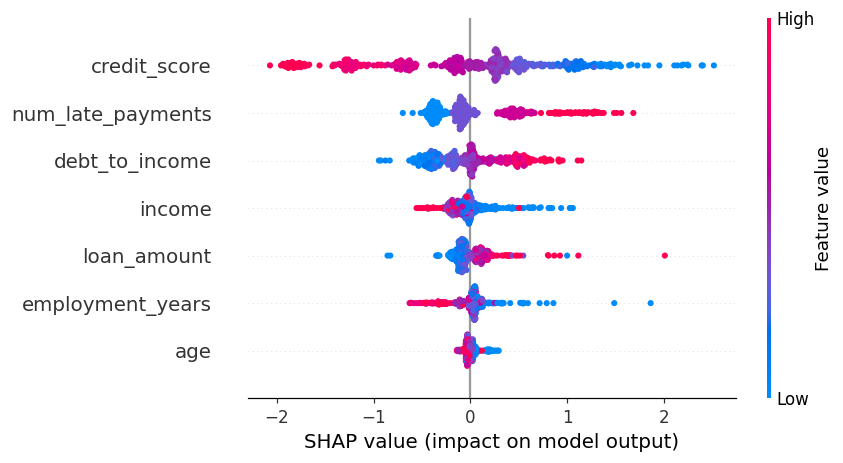


SHAP mean |value|: overall importance


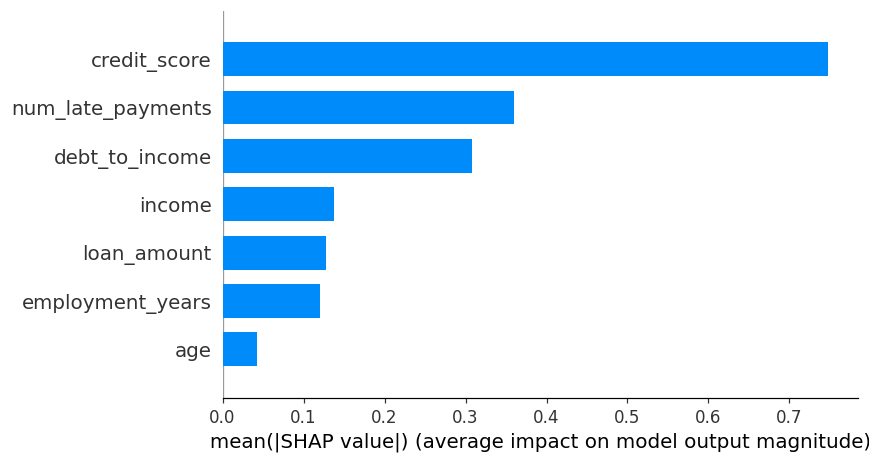


Permutation importance (model-agnostic cross-check)


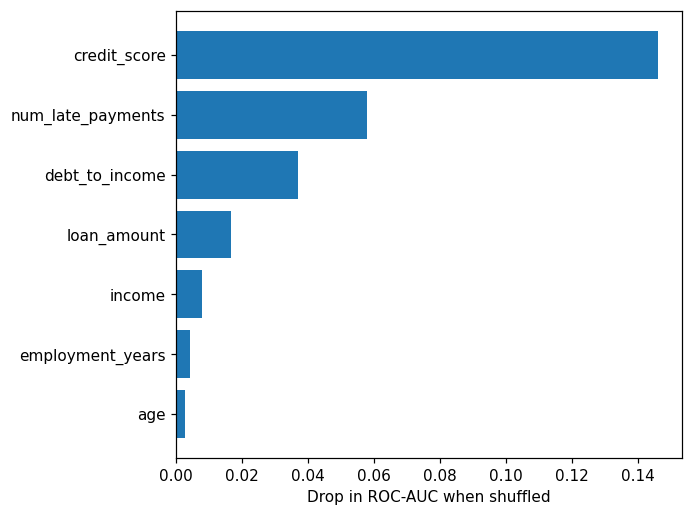


Partial dependence of top-3 features


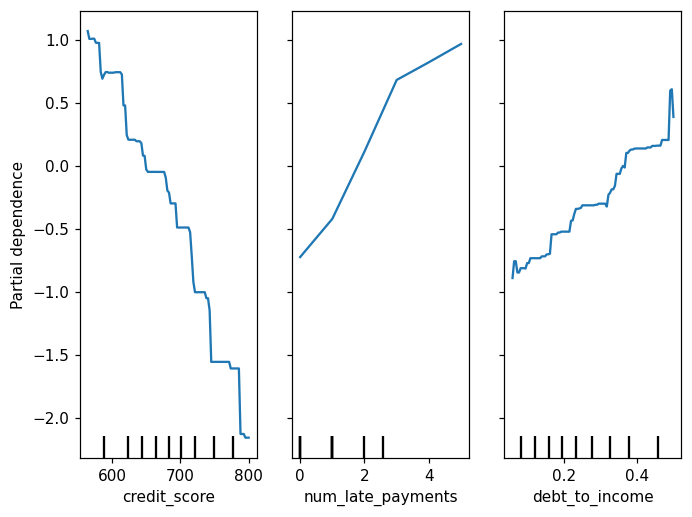

In [ ]:
for name, title in [("shap_beeswarm.png","SHAP beeswarm: direction + magnitude of each feature's effect"),
                    ("shap_bar.png","SHAP mean |value|: overall importance"),
                    ("permutation_importance.png","Permutation importance (model-agnostic cross-check)"),
                    ("partial_dependence.png","Partial dependence of top-3 features")]:
    print("\n" + title); display(Image(str(run_dir/name)))

## 6. Local explanations — *why was THIS applicant flagged?*
SHAP gives exact additive contributions; LIME gives an independent local approximation. Agreement between them builds trust.

SHAP reason codes:
{
  "probability": 0.7891,
  "base_value": -1.6563,
  "top_factors": [
    {
      "feature": "credit_score",
      "value": 580.0,
      "shap": 1.0096,
      "effect": "increases risk"
    },
    {
      "feature": "num_late_payments",
      "value": 4.0,
      "shap": 0.9214,
      "effect": "increases risk"
    },
    {
      "feature": "debt_to_income",
      "value": 0.6,
      "shap": 0.7711,
      "effect": "increases risk"
    },
    {
      "feature": "loan_amount",
      "value": 25000.0,
      "shap": 0.1713,
      "effect": "increases risk"
    },
    {
      "feature": "income",
      "value": 30000.0,
      "shap": 0.0838,
      "effect": "increases risk"
    }
  ]
}

LIME:
  credit_score <= 634.00                   +0.2556
  num_late_payments > 2.00                 +0.1832
  debt_to_income > 0.35                    +0.1207
  income <= 35094.01                       +0.0736
  loan_amount > 19631.96                   +0.0668


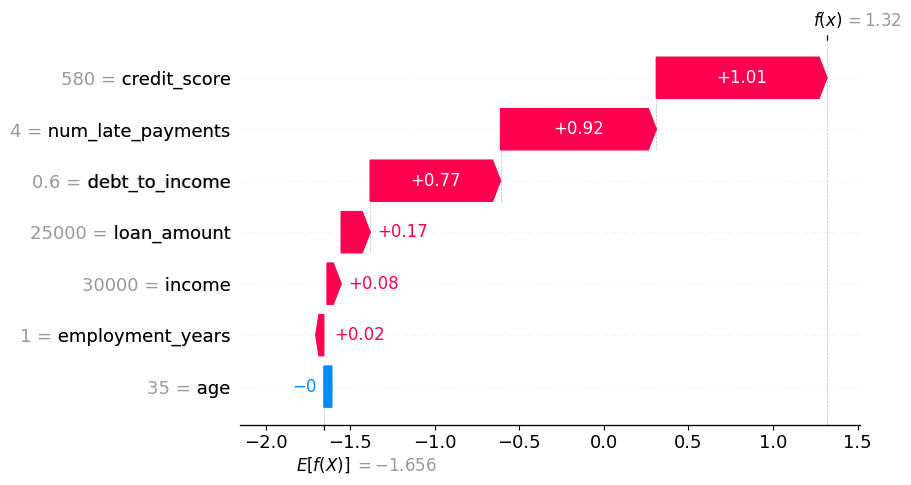

In [ ]:
risky = pd.DataFrame([{"age":35,"income":30000,"loan_amount":25000,"credit_score":580,
                       "employment_years":1,"num_late_payments":4,"debt_to_income":0.6}])[FEATURES]
ex = get_explainer(model)
print("SHAP reason codes:"); print(json.dumps(local_explanation(ex, risky), indent=2))
print("\nLIME:");
for rule, w in lime_explain(model, Xtr, risky): print(f"  {rule:40s} {w:+.4f}")

sv = shap_values(ex, risky)[0]
shap.plots.waterfall(shap.Explanation(values=sv, base_values=base_value(ex),
                     data=risky.iloc[0].values, feature_names=FEATURES))

## 7. Sanity checks (tests) — is the explanation trustworthy?
1. **Additivity:** base value + Σ SHAP = the model's log-odds output  
2. **Ground truth:** the data was generated with `credit_score`, `late payments`, `DTI` as key drivers; they should rank high

In [ ]:
sv_test = shap_values(ex, Xte.head(50))
assert np.allclose(base_value(ex) + sv_test.sum(1), model.decision_function(Xte.head(50)), atol=1e-4)
print("✅ SHAP additivity holds")

imp = pd.Series(np.abs(shap_values(ex, Xte)).mean(0), index=FEATURES).sort_values(ascending=False)
print("\nFeature ranking by mean |SHAP|:\n", imp.round(4))
assert {"num_late_payments","debt_to_income"} & set(imp.index[:3]), "explanations don't match known risk drivers!"
print("✅ Explanations recover the known drivers of risk")

✅ SHAP additivity holds

Feature ranking by mean |SHAP|:
 credit_score         0.7577
num_late_payments    0.3486
debt_to_income       0.3190
income               0.1452
loan_amount          0.1306
employment_years     0.1190
age                  0.0390
dtype: float64
✅ Explanations recover the known drivers of risk


## 8. Model serving
Loads the **champion** from the registry (not a file path), logs every request, and returns a decision + reason codes.  
In production you'd wrap these functions in FastAPI (see optional cell below).

In [ ]:
PRED_LOG = Path("prediction_log.jsonl")
_client = MlflowClient()
served = mlflow.sklearn.load_model(f"models:/{MODEL_NAME}@{CHAMPION_ALIAS}")
served_ex = get_explainer(served)
served_version = _client.get_model_version_by_alias(MODEL_NAME, CHAMPION_ALIAS).version

def predict(applicant: dict, explain=True):
    row = pd.DataFrame([applicant])[FEATURES]
    p = float(served.predict_proba(row)[0, 1])
    with open(PRED_LOG, "a") as f:                       # prediction logging for monitoring
        f.write(json.dumps({**row.iloc[0].to_dict(), "proba": p, "ts": time.time(), "model_version": served_version}) + "\n")
    out = {"default_probability": round(p, 4), "decision": "review" if p >= 0.3 else "approve", "model_version": served_version}
    if explain: out["explanation"] = local_explanation(served_ex, row, top_k=3)["top_factors"]
    return out

print(json.dumps(predict(risky.iloc[0].to_dict()), indent=2))
safe = {"age":45,"income":90000,"loan_amount":10000,"credit_score":780,"employment_years":15,"num_late_payments":0,"debt_to_income":0.1}
print(json.dumps(predict(safe), indent=2))

{
  "default_probability": 0.911,
  "decision": "review",
  "model_version": 2,
  "explanation": [
    {
      "feature": "num_late_payments",
      "value": 4.0,
      "shap": 0.9607,
      "effect": "increases risk"
    },
    {
      "feature": "debt_to_income",
      "value": 0.6,
      "shap": 0.8053,
      "effect": "increases risk"
    },
    {
      "feature": "credit_score",
      "value": 580.0,
      "shap": 0.6096,
      "effect": "increases risk"
    }
  ]
}
{
  "default_probability": 0.0279,
  "decision": "approve",
  "model_version": 2,
  "explanation": [
    {
      "feature": "credit_score",
      "value": 780.0,
      "shap": -1.4906,
      "effect": "decreases risk"
    },
    {
      "feature": "num_late_payments",
      "value": 0.0,
      "shap": -0.6102,
      "effect": "decreases risk"
    },
    {
      "feature": "debt_to_income",
      "value": 0.1,
      "shap": -0.3203,
      "effect": "decreases risk"
    }
  ]
}


## 9. Monitoring: data drift + *explanation drift*
- **PSI / KS test** per feature: did the input population change?  
- **SHAP drift:** did the model's *reasoning pattern* change? (catches problems accuracy metrics can't see without labels)

=== Healthy traffic ===


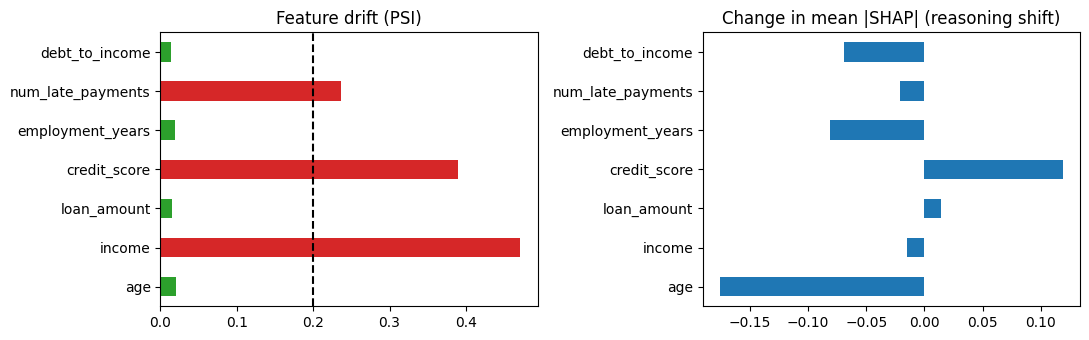

Mean prediction shift: -0.138
Drift detected: True


In [ ]:
def psi(expected, actual, bins=10):
    edges = np.unique(np.quantile(expected, np.linspace(0, 1, bins+1))); edges[0], edges[-1] = -np.inf, np.inf
    e = np.clip(np.histogram(expected, edges)[0]/len(expected), 1e-6, None)
    a = np.clip(np.histogram(actual, edges)[0]/len(actual), 1e-6, None)
    return float(np.sum((a-e)*np.log(a/e)))

def monitor(current: pd.DataFrame, label="monitoring"):
    mv = _client.get_model_version_by_alias(MODEL_NAME, CHAMPION_ALIAS)
    mdl = mlflow.sklearn.load_model(f"models:/{MODEL_NAME}@{CHAMPION_ALIAS}")
    ref = pd.read_csv(_client.download_artifacts(mv.run_id, "reference/reference.csv"))
    rep = pd.DataFrame({f: {"psi": psi(ref[f], current[f]), "ks_pvalue": ks_2samp(ref[f], current[f]).pvalue} for f in FEATURES}).T
    rep["drifted"] = rep.psi > PSI_THRESHOLD

    e = get_explainer(mdl)
    shap_shift = ((np.abs(shap_values(e, current)).mean(0) - np.abs(shap_values(e, ref)).mean(0))
                  / (np.abs(shap_values(e, ref)).mean(0) + 1e-9))
    rep["shap_rel_change"] = shap_shift
    pred_shift = float(mdl.predict_proba(current)[:,1].mean() - mdl.predict_proba(ref)[:,1].mean())

    with mlflow.start_run(run_name=label):
        mlflow.set_tags({"stage": "monitoring", "model_version": mv.version})
        mlflow.log_metric("n_drifted_features", int(rep.drifted.sum())); mlflow.log_metric("mean_pred_shift", pred_shift)
        for f in FEATURES: mlflow.log_metric(f"psi_{f}", rep.loc[f, "psi"])
        rep.to_csv(ART_DIR/f"{label}_report.csv"); mlflow.log_artifact(str(ART_DIR/f"{label}_report.csv"), "monitoring")

    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    rep.psi.plot.barh(ax=ax[0], color=["#d62728" if d else "#2ca02c" for d in rep.drifted])
    ax[0].axvline(PSI_THRESHOLD, ls="--", c="k"); ax[0].set_title("Feature drift (PSI)")
    rep.shap_rel_change.plot.barh(ax=ax[1]); ax[1].set_title("Change in mean |SHAP| (reasoning shift)")
    plt.tight_layout(); plt.show()
    print(f"Mean prediction shift: {pred_shift:+.3f}")
    return rep, bool(rep.drifted.any())

print("=== Healthy traffic ===")
_, drift_ok = monitor(make_dataset(2000, seed=7, drift=False)[FEATURES], "monitor_healthy")
print("Drift detected:", drift_ok)

=== Shifted traffic (simulated economic downturn) ===


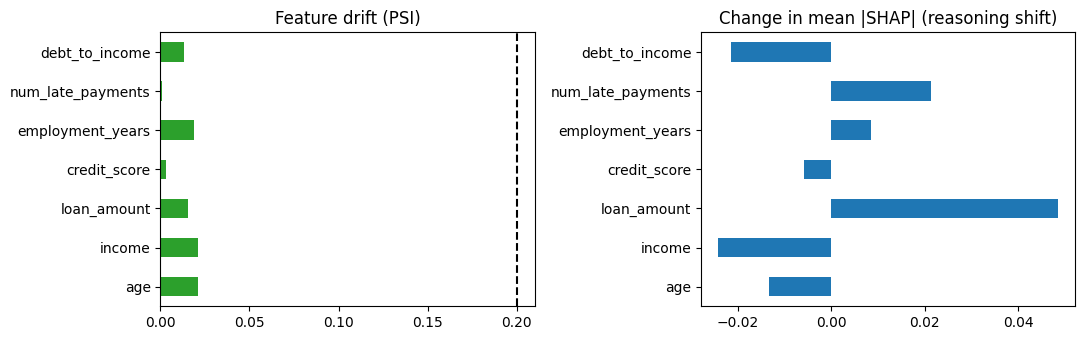

Mean prediction shift: +0.003


,psi,ks_pvalue,drifted,shap_rel_change
age,0.0209,0.7550,False,-0.0132
income,0.0214,0.3343,False,-0.0242
loan_amount,0.0156,0.5826,False,0.0486
credit_score,0.0031,0.9900,False,-0.0059
employment_years,0.0189,0.0405,False,0.0085
num_late_payments,0.0012,0.9930,False,0.0213
debt_to_income,0.0133,0.4989,False,-0.0215


Drift detected: False


In [ ]:
print("=== Shifted traffic (simulated economic downturn) ===")
report, drift_detected = monitor(make_dataset(2000, seed=7, drift=True)[FEATURES], "monitor_drifted")
display(report.round(4))
print("Drift detected:", drift_detected)

## 10. Automated retraining trigger (closing the MLOps loop)
If drift is detected → retrain on fresh data → the quality gate + champion/challenger logic decides whether the new model goes live.

In [ ]:
if drift_detected:
    print("🔁 Drift detected → retraining on the new population...")
    # In reality: fresh labelled data. Here we simulate it with the drifted generator.
    _orig = make_dataset
    make_dataset = lambda n=5000, seed=42, drift=False: _orig(n, seed, drift=True)   # train on new regime
    result = train_pipeline(seed=11)
    make_dataset = _orig

## 11. Experiment & registry overview

In [ ]:
runs = mlflow.search_runs(experiment_names=[EXPERIMENT], order_by=["start_time ASC"])
cols = [c for c in ["tags.mlflow.runName","tags.stage","tags.gate","metrics.roc_auc","metrics.n_drifted_features","tags.dataset_hash"] if c in runs.columns]
display(runs[cols])

champ_v = _client.get_model_version_by_alias(MODEL_NAME, CHAMPION_ALIAS).version
print("Registered versions:")
for mv in sorted(_client.search_model_versions(f"name='{MODEL_NAME}'"), key=lambda m: int(m.version)):
    role = "🏆 champion" if mv.version == champ_v else "archived / challenger"
    auc = _client.get_run(mv.run_id).data.metrics["roc_auc"]
    print(f"  v{mv.version}  {role:22s} AUC={auc:.4f}  run={mv.run_id[:8]}")

,tags.mlflow.runName,tags.stage,tags.gate,metrics.roc_auc,metrics.n_drifted_features,tags.dataset_hash
0,train,training,passed,0.753122,NaN,008dbc3d9d26
1,monitor_healthy,monitoring,None,NaN,0.0,None
2,monitor_drifted,monitoring,None,NaN,3.0,None
3,train,training,passed,0.756606,NaN,247120578e30
4,train,training,passed,0.753122,NaN,008dbc3d9d26
5,monitor_healthy,monitoring,None,NaN,3.0,None
6,monitor_drifted,monitoring,None,NaN,0.0,None


Registered versions:
  v1  archived / challenger  AUC=0.7531  run=6d918484
  v2  🏆 champion             AUC=0.7566  run=754fc804
  v3  archived / challenger  AUC=0.7531  run=0fb5079e


## 12.Open the MLflow
```python
!pip install -q pyngrok
from pyngrok import ngrok
ngrok.set_auth_token("YOUR_NGROK_TOKEN")     # free token from ngrok.com
get_ipython().system_raw("mlflow ui --backend-store-uri sqlite:///mlflow.db --port 5000 &")
print(ngrok.connect(5000))
```

## Summary
| Stage | What we did |
|---|---|
| Data | Synthetic, versioned by content hash |
| Train | GradientBoosting, params/metrics logged in MLflow |
| XAI | SHAP, LIME, permutation importance, PDP, reason codes |
| Trust | Additivity test + ground-truth driver check |
| Registry | Quality gate → register → champion/challenger promotion |
| Serve | Champion loaded by alias, predictions logged, explanations returned |
| Monitor | PSI/KS data drift + SHAP explanation drift |
| Loop | Drift → retrain → gate → promote |